# Course Code: DT8013
# Course Name: Data Mining
# Lab Session: Interestingness

### This lab is due on the 21/10/2026.
### Save the notebook: 'yourname_interestingness.ipynb' and submit by the due date.



In this lab, you will learn about association rule mining. You will use basic Python libraries, the Apriori library (https://efficient-apriori.readthedocs.io/en/latest/) and the Networkx library (https://networkx.org). Please save the file in the following format 'lab_interestingness_yourname.ipynb' and submit by the due date.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
%matplotlib inline
import seaborn as sns
import warnings
warnings.simplefilter('ignore')
from PIL import Image

# Interestingness

### Interestingness through Market-Basket analysis

Market Basket Analysis is one of the key techniques used by large retailers to uncover associations between items. It works by looking for combinations of items that occur together frequently in transactions.

Association Rules are widely used to analyze retail basket or transaction data, and are intended to identify strong rules discovered in transaction data using measures of interestingness, based on the concept of strong rules.

### Apriori algorithm

The Apriori algorithm generates association rules for a given data set. An association rule implies that if an item A occurs, then item B also occurs with a certain probability. Let's look at an example.

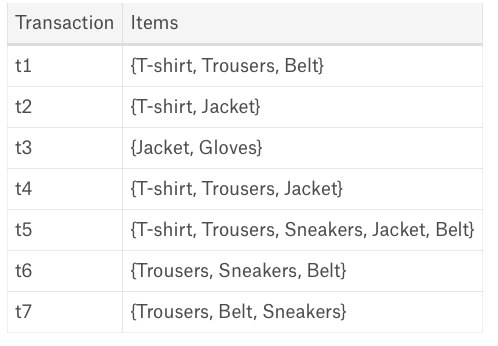

In [2]:
from IPython.display import Image
Image(filename='Images/market_basket.v1.png')

In the table above seven transactions from a clothing store are shown. Each transaction shows items bought in that transaction. We can represent our items as an item set as follows

$$ I = (i_1,i2,..., in) $$

                                        
In this case it will be:

                               
                                {T-shirt,Trousers,Belt,Jacket,Gloves,Sneakers}

A transaction is represented by the following expression:

$$  T = {t_1,i_2,..., t_k} $$

For instance

                                        T = {T-shirt,Trousers,Belt}

Then, an association rule is defined as an implication of the form:

$$ X=>Y, where  \quad  X ,  Y \subset I  \quad and \quad X \cap Y = 0 $$

For instance,
                                   
                                             {T-shirt, Trousers} => {Belt}
                    

## Interestingness Measures

- Support
- Confidence
- Lift
- Conviction

### Support

Support is a measure of how frequently the itemset appears in the dataset.

$$ supp(X=>Y) = \frac{X\cap Y}{n}  $$

In other words, support is the number of transactions with both X and Y divided by the total number of records.

<div class='alert alert-block alert-success' style="font-weight:bolder">

### Task1 (1 pt)

Calculate the support of the following rules. Write your answers belows. One of the examples has already been calculated for you.

</div>

Let's look at some association rules with their supports calculated.

$ supp(Trousers => Jacket) = \frac{2}{7}=28.57\%$ 

$ supp(T-shirt => Trousers) = \frac{3}{7}=43\%$

$ supp(Trousers => Belt) = \frac{4}{7}=57.14\% $

$ supp(T-shirt => Belt) = \frac{2}{7}=28.57\%$

$ supp(T-shirt,Trousers => Belt ) = \frac{2}{7}=28.57\%$

### Confidence

In an association rule X => Y, given that X occured, confidence is the frequency of Y happening. Mathematically, it is defined as follows:

$$ conf(X=>Y) = \frac{supp(X,Y)}{supp(X)} $$ 


<div class='alert alert-block alert-success' style="font-weight:bolder">

### Task2 (1 pt)

Calculate the confidence of the following rules.

</div>

$ conf(Sneaekrs => T-shirt)=\frac{1}{3}=33.33\%$

$ conf(T-shirt => Jacket) =\frac{3}{4}=75\% $

$ conf( \{Trousers, Belt\} => Sneakers) =\frac{3}{4}=75\% $

### Lift

Lift is the ratio of the observed support to that expected if X and Y were independent. Lift is defined as follows:

$$ lift(X=>Y) = \frac{supp(X , Y)}{supp(X)supp(Y)} $$ 

• Lift = 1: X and Y are independent (no real relation).
• Lift > 1: positively associated.
• Lift < 1: negatively associated

<div class='alert alert-block alert-success' style="font-weight:bolder">

### Task3 (1 pt)

Calculate the lift of the following rules.

</div>

$ lift(Trousers => Jacket) = \frac{0.4}{0.571}=0.70\% $

$ lift( \{T-shirt,Belt\} => Trousers) = \frac{1}{0.714}=1.4\% $

$ lift( T-shirt => Sneakers) = \frac{0.25}{0.429}=0.58\% $

### Conviction

Conviction can be interpreted as the ratio of the expected frequency that X occurs without Y (that is to say, the frequency that the rule makes an incorrect prediction) if X and Y were independent divided by the observed frequency of incorrect predictions. Mathematically, conviction is defined as follows:

$$ conv(X=>Y) = \frac{1-supp(Y)}{1-conf(X=>Y)}  $$

Conviction 1 means X and Y are independent.
Conviction below 1 (the first and third rules) means the rule is wrong more often than independence would predict. This agrees with Task 3, where those rules had lift below 1 (0.70 and 0.58): they are negatively associated.
Conviction ∞ (the second rule) means the rule was never wrong in this data, because its confidence is 1. It agrees with its lift of 1.4. But it rests on only 2 of the 7 transactions (support about 29%), so it is weak evidence from a tiny table.

<div class='alert alert-block alert-success' style="font-weight:bolder">

### Task4 (1 pt)

Calculate the conviction of the following rules.

</div>

$ conv(Trousers => Jacket) =\frac{1-(4/7)}{1-(2/5)}=\frac{3/7}{3/5}=\frac{5}{7}=0.71 $

$ conv( \{T-shirt,Belt\} => Trousers) =\frac{1-(5/7)}{1-1}=\frac{2/7}{0}=\infty $

$ conv( T-shirt => Sneakers)=\frac{1-(3/7)}{1-(1/4)}=\frac{4/7}{3/4}=\frac{16}{21}=0.76  $

## Analysing interestingness measures on a real-world dataset

The dataset contains 15010 records(transactions) each with four columns. The description of the columns are as follows:

- Date: Indicates date of trasaction (YYYY-MM-DD format). It ranges from 30/10/2016 to 09/04/2017
- Time: Time of transaction (HH:MM:SS format)
- Transaction: Categorical variable which allows to differentiate between transactions. Those rows that share the same transaction code belong to the same transaction. 
- Item: Categorical variables shows items of transactions

In [3]:
data = pd.read_csv('BreadBasket_DMS.csv')
data

,Date,Time,Transaction,Item
0,2016-10-30,09:58:11,1,Bread
1,2016-10-30,10:05:34,2,Scandinavian
2,2016-10-30,10:05:34,2,Scandinavian
3,2016-10-30,10:07:57,3,Hot chocolate
4,2016-10-30,10:07:57,3,Jam
...,...,...,...,...
21288,2017-04-09,14:32:58,9682,Coffee
21289,2017-04-09,14:32:58,9682,Tea
21290,2017-04-09,14:57:06,9683,Coffee
21291,2017-04-09,14:57:06,9683,Pastry


<div class='alert alert-block alert-success' style="font-weight:bolder">

### Task5 (1 pt)

- Plot the items against their corresponding frequencies as a bar plot.

- Plot number of transactions per month.

- Plot number of transactions per weekday.

- Plot number of transactions per hour.

</div>

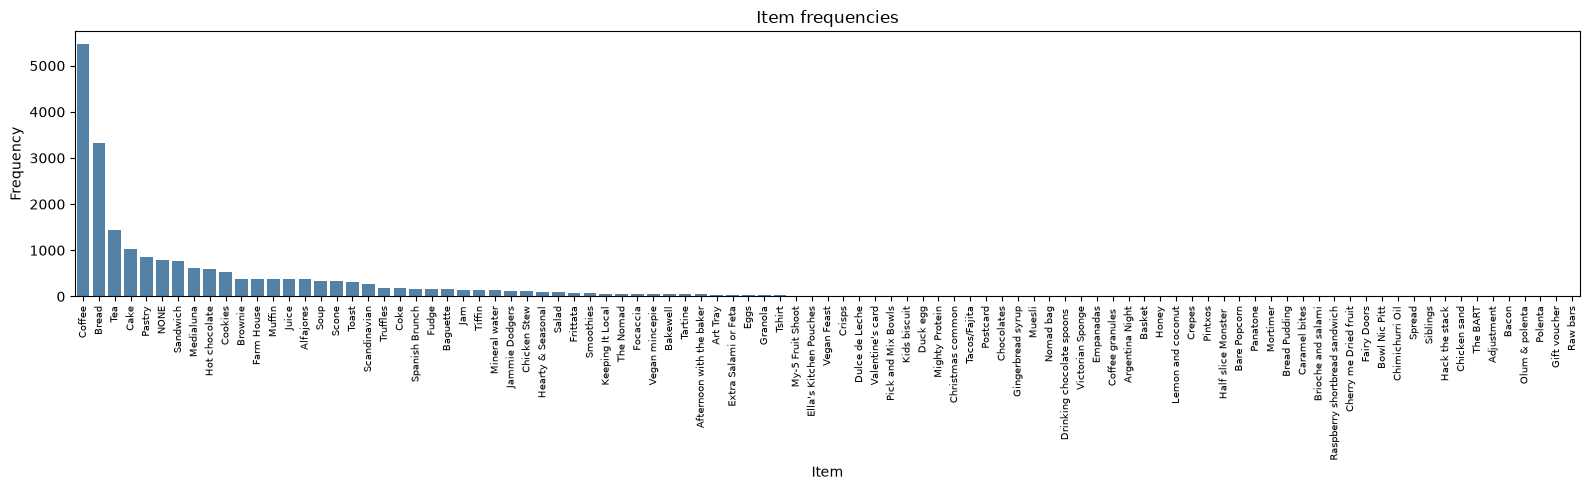

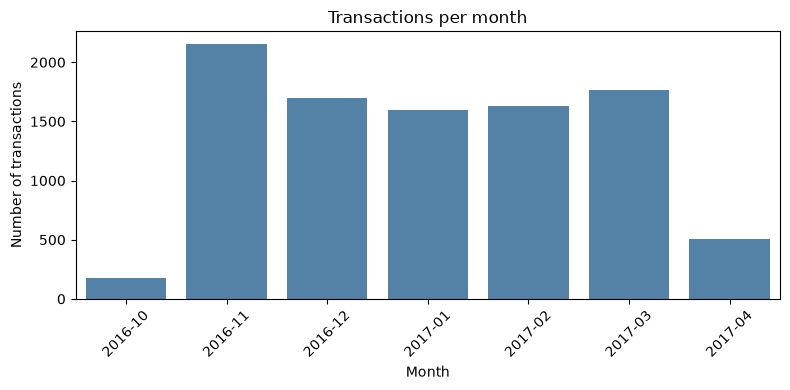

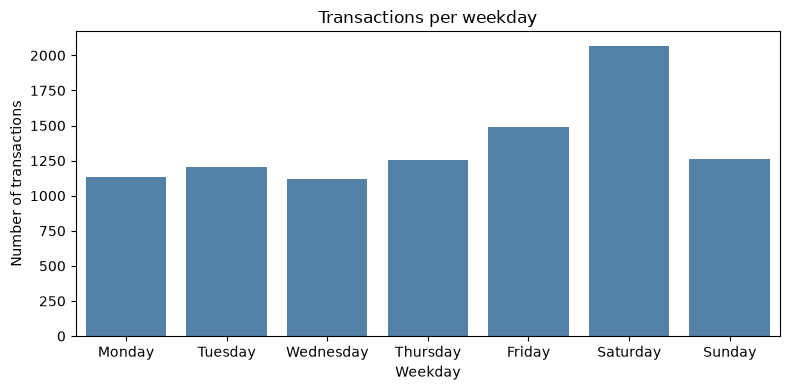

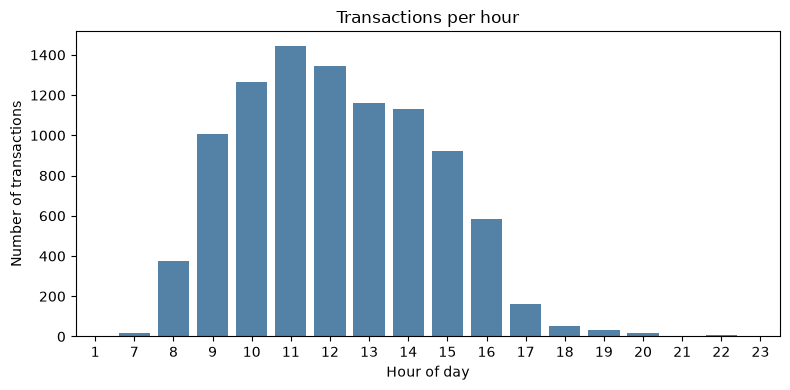

In [4]:
#Please implement Task 5 here

df = data.copy()    # keep original data safe
df['Date'] = pd.to_datetime(df['Date']) #plain text date to real date 

# 1. Items Vs Corresponding Frequencies 
item_counts = data['Item'].value_counts()
plt.figure(figsize=(16, 5))
sns.barplot(x=item_counts.index, y=item_counts.values, color='steelblue')
plt.xticks(rotation=90, fontsize=7)
plt.xlabel('Item')
plt.ylabel('Frequency')
plt.title('Item frequencies')
plt.tight_layout()
plt.show()

trans = df.drop_duplicates(subset='Transaction').copy() #one purcase -> one transaction => multiple items -> different rows 


# 2. Number of transaction per month 
trans['Month'] = trans['Date'].dt.to_period('M')
per_month = trans['Month'].value_counts().sort_index()
plt.figure(figsize=(8, 4))
sns.barplot(x=per_month.index.astype(str), y=per_month.values, color='steelblue')
plt.xlabel('Month')
plt.ylabel('Number of transactions')
plt.title('Transactions per month')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# 3. Number of transaction per week day 
trans['Weekday'] = trans['Date'].dt.day_name()
order = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']
per_weekday = trans['Weekday'].value_counts().reindex(order)
plt.figure(figsize=(8, 4))
sns.barplot(x=per_weekday.index, y=per_weekday.values, color='steelblue')
plt.xlabel('Weekday')
plt.ylabel('Number of transactions')
plt.title('Transactions per weekday')
plt.tight_layout()
plt.show()

# 4. NUmber of transaction per hour 
trans['Hour'] = pd.to_datetime(trans['Time'], format='%H:%M:%S').dt.hour
per_hour = trans['Hour'].value_counts().sort_index()
plt.figure(figsize=(8, 4))
sns.barplot(x=per_hour.index, y=per_hour.values, color='steelblue')
plt.xlabel('Hour of day')
plt.ylabel('Number of transactions')
plt.title('Transactions per hour')
plt.tight_layout()
plt.show()


## Finding 
1. Coffe, Bread -> Dominates the sales 
2. Nov, 2026 -> Highest sales
3. Oct, 2026 and April 2027 -> Lowest sales cz the datas of these  months are it self less 
4. Saturday -> Busiest dat 
5. 11:00 -> Peak hours , while 9:00 to 15:00 -> active hour 


## Apriori Algorithm

Apriori is an algorithm for frequent item set mining and association rule learning over transactional databases. It proceeds by identifying the frequent individual items in the database and extending them to larger and larger item sets as long as those item sets appear sufficiently often in the database.

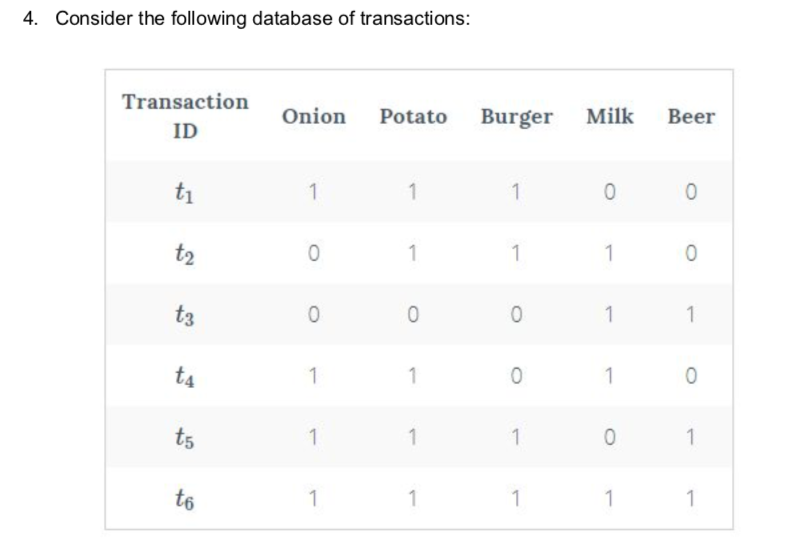

In [5]:
Image(filename='Images/Apriori0.png')

1- We create a frequency table of all the items that occur in all the transactions. 

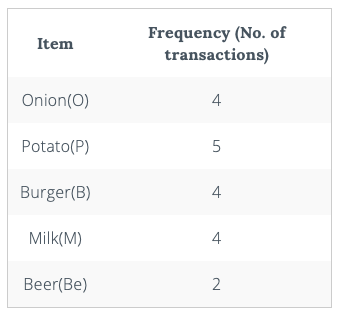

In [6]:
Image(filename='Images/Apriori.v1.png')

2- We know that elements are significant when the support is greater than or equal to the threshold support.
Here, support threshold is 50%, hence the significant items are those which occur in more than three transactions and such items are Onion(O), Potato(P), Burger(B), and Milk(M). Therefore, we are left with:

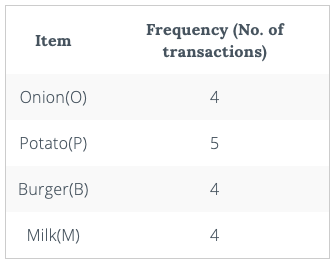

In [7]:
Image(filename='Images/Apriori.v2.png')

3- The next step is to make all the possible pairs of the significant items keeping in mind that the order doesn’t matter, i.e., AB is same as BA. To do this, take the first item and pair it with all the others such as OP, OB, OM. Similarly, consider the second item and pair it with preceding items, i.e., PB, PM. We are only considering the preceding items because PO (same as OP) already exists. So, all the pairs in our example are OP, OB, OM, PB, PM, BM.

4- We will now count the occurrences of each pair in all the transactions.

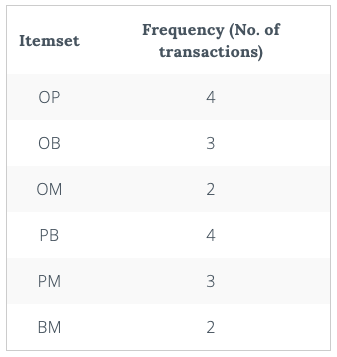

In [8]:
Image(filename='Images/Apriori.v4.png')

5- Again only those itemsets are significant which cross the support threshold, and those are OP, OB, PB, and PM.

6- Now let’s say we would like to look for a set of three items that are purchased together. We will use the itemsets found in step 5 and create a set of 3 items.

To create a set of 3 items another rule, called self-join is required. It says that from the item pairs OP, OB, PB and PM we look for two pairs with the identical first letter and so we get

OP and OB, this gives OPB, 
PB and PM, this gives PBM
Next, we find the frequency for these two itemsets.

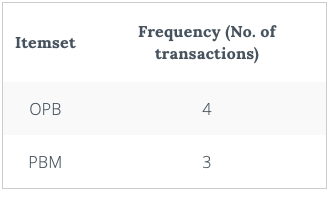

In [9]:
Image(filename='Images/Apriori.v6.png')

## Python apriori library 

In [10]:
# pip install efficient-apriori

In [11]:
from efficient_apriori import apriori

In [12]:
data

,Date,Time,Transaction,Item
0,2016-10-30,09:58:11,1,Bread
1,2016-10-30,10:05:34,2,Scandinavian
2,2016-10-30,10:05:34,2,Scandinavian
3,2016-10-30,10:07:57,3,Hot chocolate
4,2016-10-30,10:07:57,3,Jam
...,...,...,...,...
21288,2017-04-09,14:32:58,9682,Coffee
21289,2017-04-09,14:32:58,9682,Tea
21290,2017-04-09,14:57:06,9683,Coffee
21291,2017-04-09,14:57:06,9683,Pastry


In [13]:
data_itemset = data.groupby('Transaction')['Item'].apply(pd.Series.tolist).tolist()
data_itemset

[['Bread'],
 ['Scandinavian', 'Scandinavian'],
 ['Hot chocolate', 'Jam', 'Cookies'],
 ['Muffin'],
 ['Coffee', 'Pastry', 'Bread'],
 ['Medialuna', 'Pastry', 'Muffin'],
 ['Medialuna', 'Pastry', 'Coffee', 'Tea'],
 ['Pastry', 'Bread'],
 ['Bread', 'Muffin'],
 ['Scandinavian', 'Medialuna'],
 ['Bread', 'Medialuna', 'Bread', 'NONE'],
 ['Jam', 'Coffee', 'Tartine', 'Pastry', 'Tea'],
 ['Basket', 'Bread', 'Coffee'],
 ['Bread', 'Medialuna', 'Pastry'],
 ['NONE', 'NONE', 'Mineral water', 'Scandinavian'],
 ['Bread', 'Medialuna', 'Coffee'],
 ['Hot chocolate'],
 ['Farm House'],
 ['Farm House', 'Bread'],
 ['Bread', 'Medialuna'],
 ['Coffee', 'Coffee', 'Medialuna', 'Bread'],
 ['Jam'],
 ['Scandinavian', 'Muffin'],
 ['Bread'],
 ['Scandinavian'],
 ['Fudge'],
 ['Scandinavian'],
 ['Coffee', 'Bread'],
 ['Bread', 'Jam', 'NONE'],
 ['Bread'],
 ['Basket'],
 ['Scandinavian', 'Muffin'],
 ['Coffee'],
 ['Coffee', 'Muffin'],
 ['Muffin', 'Scandinavian'],
 ['Tea', 'Bread'],
 ['Coffee', 'Bread', 'NONE'],
 ['Bread', 'Tea'],
 

In [14]:
for i in range(len(data_itemset)):
    data_itemset[i] = tuple(data_itemset[i])


In [15]:
itemsets, rules = apriori(data_itemset[0:], min_support=.01,  min_confidence=.1)
rules

[{Alfajores} -> {Bread},
 {Alfajores} -> {Coffee},
 {Brownie} -> {Bread},
 {Cake} -> {Bread},
 {Coffee} -> {Bread},
 {Bread} -> {Coffee},
 {Cookies} -> {Bread},
 {Hot chocolate} -> {Bread},
 {Medialuna} -> {Bread},
 {NONE} -> {Bread},
 {Pastry} -> {Bread},
 {Sandwich} -> {Bread},
 {Tea} -> {Bread},
 {Brownie} -> {Coffee},
 {Coffee} -> {Cake},
 {Cake} -> {Coffee},
 {Hot chocolate} -> {Cake},
 {Cake} -> {Hot chocolate},
 {Tea} -> {Cake},
 {Cake} -> {Tea},
 {Cookies} -> {Coffee},
 {Hot chocolate} -> {Coffee},
 {Juice} -> {Coffee},
 {Medialuna} -> {Coffee},
 {Muffin} -> {Coffee},
 {NONE} -> {Coffee},
 {Pastry} -> {Coffee},
 {Sandwich} -> {Coffee},
 {Scone} -> {Coffee},
 {Soup} -> {Coffee},
 {Spanish Brunch} -> {Coffee},
 {Tea} -> {Coffee},
 {Coffee} -> {Tea},
 {Toast} -> {Coffee},
 {Tea} -> {NONE},
 {NONE} -> {Tea},
 {Tea} -> {Sandwich},
 {Sandwich} -> {Tea},
 {Coffee, Pastry} -> {Bread},
 {Bread, Pastry} -> {Coffee},
 {Bread, Coffee} -> {Pastry},
 {Pastry} -> {Bread, Coffee}]

In [16]:
itemsets

{1: {('Bread',): 3097,
  ('Scandinavian',): 275,
  ('Hot chocolate',): 552,
  ('Jam',): 142,
  ('Cookies',): 515,
  ('Muffin',): 364,
  ('Coffee',): 4528,
  ('Pastry',): 815,
  ('Medialuna',): 585,
  ('Tea',): 1350,
  ('NONE',): 753,
  ('Mineral water',): 134,
  ('Farm House',): 371,
  ('Fudge',): 142,
  ('Juice',): 365,
  ('Hearty & Seasonal',): 100,
  ('Soup',): 326,
  ('Cake',): 983,
  ('Coke',): 184,
  ('Sandwich',): 680,
  ('Alfajores',): 344,
  ('Brownie',): 379,
  ('Truffles',): 192,
  ('Jammie Dodgers',): 125,
  ('Tiffin',): 146,
  ('Toast',): 318,
  ('Scone',): 327,
  ('Salad',): 99,
  ('Chicken Stew',): 123,
  ('Spanish Brunch',): 172,
  ('Baguette',): 152},
 2: {('Alfajores', 'Bread'): 98,
  ('Alfajores', 'Coffee'): 186,
  ('Bread', 'Brownie'): 102,
  ('Bread', 'Cake'): 221,
  ('Bread', 'Coffee'): 852,
  ('Bread', 'Cookies'): 137,
  ('Bread', 'Hot chocolate'): 127,
  ('Bread', 'Medialuna'): 160,
  ('Bread', 'NONE'): 196,
  ('Bread', 'Pastry'): 276,
  ('Bread', 'Sandwich'): 1

The apriori() function, returns both the itemsets and the association rules for the specified support and confidence levels.

<div class='alert alert-block alert-success' style="font-weight:bolder">

### Task6 (1 pt)

- Run apriori algorithm for different min_support and a fixed min_confidence and plot a graph with x axis min_support and y-axis to be the number of rules generated.


- Run apriori algorithm for different min_confidence and a fixed min_support and plot a graph with x axis min_support and y-axis to be the number of rules generated.

</div>

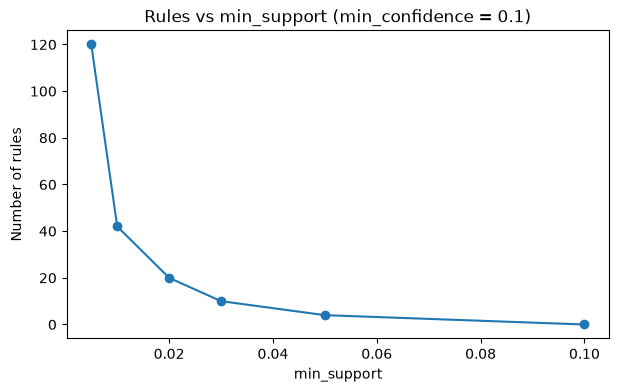

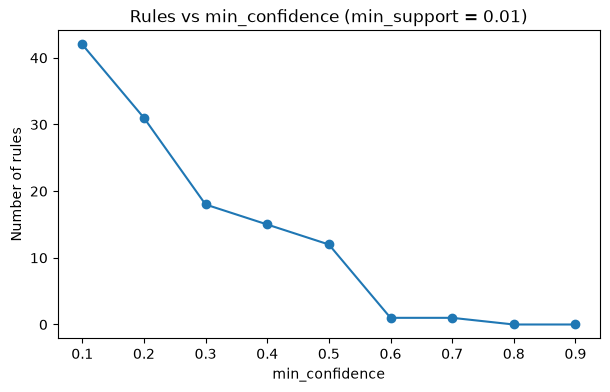

In [17]:
#please implement Task 6 here
# 1: vary min_support, keep min_confidence fixed
supports = [0.005, 0.01, 0.02, 0.03, 0.05, 0.1]
rules_vs_support = []

for s in supports:
    itemsets, rulesSupport = apriori(data_itemset, min_support=s, min_confidence=0.1)
    rules_vs_support.append(len(rulesSupport))

plt.figure(figsize=(7, 4))
plt.plot(supports, rules_vs_support, marker='o')
plt.xlabel('min_support')
plt.ylabel('Number of rules')
plt.title('Rules vs min_support (min_confidence = 0.1)')
plt.show()

# 2: vary min_confidence, keep min_support fixed
confidences = [0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9]
rules_vs_confidence = []

for c in confidences:
    itemsets, rulesConfidence = apriori(data_itemset, min_support=0.01, min_confidence=c)
    rules_vs_confidence.append(len(rulesConfidence))

plt.figure(figsize=(7, 4))
plt.plot(confidences, rules_vs_confidence, marker='o')
plt.xlabel('min_confidence')
plt.ylabel('Number of rules')
plt.title('Rules vs min_confidence (min_support = 0.01)')
plt.show()

### Finding:
1. Support: Most rules come from combinations that appear in only 0.5% to 2% of baskets.
2. Confidence: most rules are weak or moderate (at or below 0.5)
3. Practical choice: min_support around 0.01 to 0.03 and min_confidence around 0.3 to 0.5 give a readable 10 to 40 rules.


## Visualization Association Rules

Below we define a method using the networkx library to visualize our association rules through a graph structure

In [18]:
import networkx as nx


def draw_graph(rules, rules_to_show):
    
    G1 = nx.DiGraph()

    color_map = []
    N = 50
    colors = np.random.rand(N)
    strs = ['R0', 'R1', 'R2', 'R3', 'R4', 'R5', 'R6', 'R7', 'R8', 'R9', 'R10', 'R11']

    for i in range(rules_to_show):
        G1.add_nodes_from(["R" + str(i)])

        for a in rules[i].lhs:
            G1.add_nodes_from([a])
            G1.add_edge(a, "R" + str(i), color=colors[i], weight=2)

        for c in rules[i].rhs:
            G1.add_edge("R" + str(i), c, color=colors[i], weight=2)

    for node in G1.nodes():
        found_a_string = False
        for item in strs:
            if node == item:
                found_a_string = True
        if found_a_string:
            color_map.append('yellow')
        else:
            color_map.append('green')

    edges = G1.edges()
    print(edges)
    colors = [G1[u][v]['color'] for u, v in edges]
    weights = [G1[u][v]['weight'] for u, v in edges]

    pos = nx.spring_layout(G1, k=16, scale=1)
    
    # Draw the graph with labels
    nx.draw(G1, pos, edgelist=edges, node_color=color_map, edge_color=colors, width=weights, font_size=16, with_labels=False)
    
    for p in pos:  
        pos[p][1] += 0.07
    nx.draw_networkx_labels(G1, pos)
    
    plt.show()


[('R0', 'Coffee'), ('Spanish Brunch', 'R0'), ('Coffee', 'R2'), ('Coffee', 'R8'), ('R1', 'Coffee'), ('Tea', 'R1'), ('Tea', 'R4'), ('Tea', 'R6'), ('R2', 'Tea'), ('R3', 'Coffee'), ('Toast', 'R3'), ('R4', 'NONE'), ('NONE', 'R5'), ('R5', 'Tea'), ('R6', 'Sandwich'), ('Sandwich', 'R7'), ('R7', 'Tea'), ('R8', 'Bread'), ('Pastry', 'R8'), ('Pastry', 'R9'), ('Bread', 'R9'), ('R9', 'Coffee')]


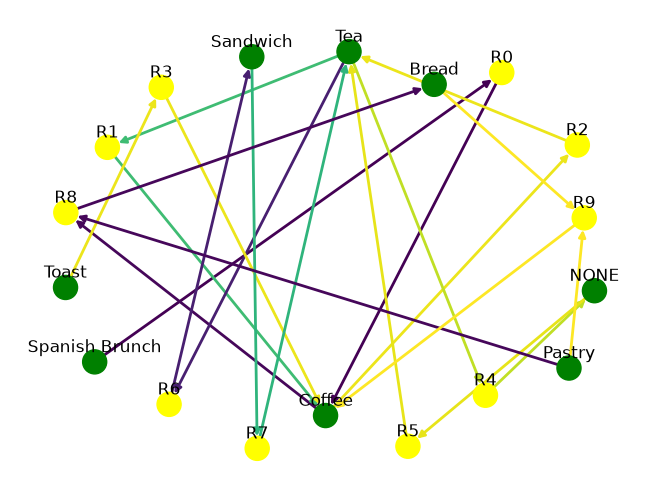

In [19]:
# We visualize a structure here
draw_graph(rules[30:40], 10)


<div class='alert alert-block alert-success' style="font-weight:bolder">

### Task7 (1 pt)

Draw a graph that shows a consequence and precedence for each rule around it.

More concretely consider consequence to be "Bread" and choose at most 12 rules.

</div>

12 rules end in Bread
[('R0', 'Bread'), ('Pastry', 'R0'), ('Pastry', 'R7'), ('R1', 'Bread'), ('Alfajores', 'R1'), ('R2', 'Bread'), ('Medialuna', 'R2'), ('R3', 'Bread'), ('Brownie', 'R3'), ('R4', 'Bread'), ('Cookies', 'R4'), ('R5', 'Bread'), ('NONE', 'R5'), ('R6', 'Bread'), ('Sandwich', 'R6'), ('R7', 'Bread'), ('Coffee', 'R7'), ('Coffee', 'R11'), ('R8', 'Bread'), ('Hot chocolate', 'R8'), ('R9', 'Bread'), ('Cake', 'R9'), ('R10', 'Bread'), ('Tea', 'R10'), ('R11', 'Bread')]


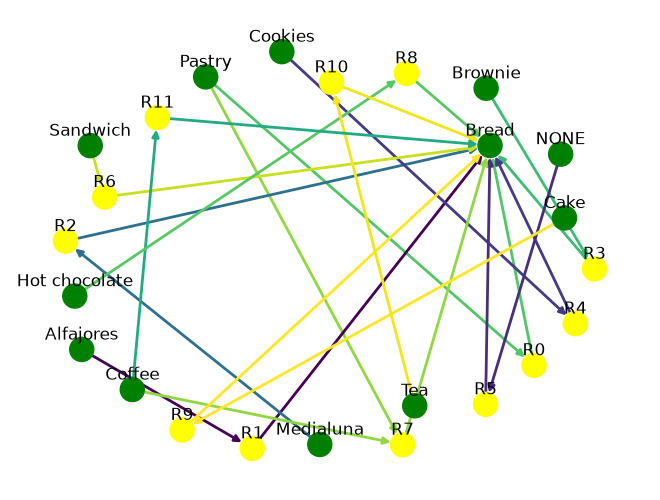

In [20]:
#Please implement Task 7 here

# 1. Get items and ruleset 
itemsetsNew, rulesNew = apriori(data_itemset, min_support=.01, min_confidence=.1)

# 2. keep only rules where the consequence (right side) is Bread
bread_rules = [r for r in rulesNew if r.rhs == ('Bread',)]
print(len(bread_rules), "rules end in Bread")

# 3. strongest first (by confidence), at most 12
bread_rules = sorted(bread_rules, key=lambda r: r.confidence, reverse=True)[:12]

# 4. draw
draw_graph(bread_rules, len(bread_rules))


<div class='alert alert-block alert-success' style="font-weight:bolder">

### Task8 (2 pts)

In the default credit dataset, try to find the following:

- Find a concise pattern.
- Find a general pattern.
- Find a peculiar pattern.

Use the definition of conciseness, generality and peculiarity from your lecture notes. 
Additionally, you can also read more from this paper:

https://www.researchgate.net/publication/220566216_Interestingness_Measures_for_Data_Mining_A_Survey
    

</div>

In [21]:

credit_dataset = pd.read_csv('default_credit_card_clients.csv')
credit_dataset

,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_0,PAY_2,PAY_3,PAY_4,PAY_5,...,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,default payment next month
0,20000,2,2,1,24,2,2,-1,-1,-2,...,0,0,0,0,689,0,0,0,0,1
1,120000,2,2,2,26,-1,2,0,0,0,...,3272,3455,3261,0,1000,1000,1000,0,2000,1
2,90000,2,2,2,34,0,0,0,0,0,...,14331,14948,15549,1518,1500,1000,1000,1000,5000,0
3,50000,2,2,1,37,0,0,0,0,0,...,28314,28959,29547,2000,2019,1200,1100,1069,1000,0
4,50000,1,2,1,57,-1,0,-1,0,0,...,20940,19146,19131,2000,36681,10000,9000,689,679,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
29995,220000,1,3,1,39,0,0,0,0,0,...,88004,31237,15980,8500,20000,5003,3047,5000,1000,0
29996,150000,1,3,2,43,-1,-1,-1,-1,0,...,8979,5190,0,1837,3526,8998,129,0,0,0
29997,30000,1,2,2,37,4,3,2,-1,0,...,20878,20582,19357,0,0,22000,4200,2000,3100,1
29998,80000,1,3,1,41,1,-1,0,0,0,...,52774,11855,48944,85900,3409,1178,1926,52964,1804,1


**Data set description link:**
https://archive.ics.uci.edu/dataset/350/default+of+credit+card+clients


In [22]:
# 1. Data set shape 
df = credit_dataset
target = 'default payment next month' # cz it has something to tell, valuable, reliable and binary for easy comparision 

print(df.shape)
print("Overall default rate:", round(df[target].mean(), 3))

# 2. Evaluation function 
def evaluate(name, mask, n_conditions):
    coverage = mask.mean()                       # share of clients matching the pattern
    default_rate = df.loc[mask, target].mean()   # share of those who default >> fraction of true values which is a coverage
    print(f"{name}\n   conditions: {n_conditions} | coverage: {coverage:.1%} | default rate: {default_rate:.1%}\n")

(30000, 24)
Overall default rate: 0.221


**Note** Distance from baseline :
1. gretater  -> Informative 
2. Smaller(Near) -> Uinformative

In [23]:
# 3. Consise Pattern : Check for consise pattern , one condition

# 3.1. Client payment 2 or more months late 
evaluate("PAY_0 >= 2", df['PAY_0'] >= 2, 1)

# 3.2. Check if the client is female -> true for women 
evaluate("SEX == 2", df['SEX'] == 2, 1)

# 3.3. Check for married client -> true for married
evaluate("MARRIAGE == 1", df['MARRIAGE'] == 1, 1)

# for contrast, a long, not-concise pattern
evaluate("PAY_0 >= 2 & PAY_2 >= 2 & SEX == 2 & EDUCATION == 2",
         (df['PAY_0'] >= 2) & (df['PAY_2'] >= 2) & (df['SEX'] == 2) & (df['EDUCATION'] == 2), 4)

PAY_0 >= 2
   conditions: 1 | coverage: 10.4% | default rate: 69.6%

SEX == 2
   conditions: 1 | coverage: 60.4% | default rate: 20.8%

MARRIAGE == 1
   conditions: 1 | coverage: 45.5% | default rate: 23.5%

PAY_0 >= 2 & PAY_2 >= 2 & SEX == 2 & EDUCATION == 2
   conditions: 4 | coverage: 2.2% | default rate: 71.3%



**Finding:** 
1. PAY_0 >= 2 → default = 1 : has a single condition, covering 10% of client with default rate of approx 70%
2. Sex and the marraige rasie the default rate but covers very less 
3. Thus with PAY_0 >=2 , addition of other condition do not add much useful information

In [24]:
# 4. General Pattern: Large and common coverage 
    # PAY_0 : Payment status in the last month 
    # <=0 -> not late , paid on time 
    # 0 -> paid the minimum 
    # >0 -> above months late 
evaluate("PAY_0 <= 0", df['PAY_0'] <= 0, 1) 
    # EDUCATION <= 2 : 1 - graduated , 2 university , 3 - high school, 4 others
evaluate("EDUCATION <= 2", df['EDUCATION'] <= 2, 1)
    # AGE between 25 and 45 : Workign age customer
evaluate("AGE between 25 and 45", (df['AGE'] >= 25) & (df['AGE'] <= 45), 2)

PAY_0 <= 0
   conditions: 1 | coverage: 77.3% | default rate: 13.8%

EDUCATION <= 2
   conditions: 1 | coverage: 82.1% | default rate: 21.8%

AGE between 25 and 45
   conditions: 2 | coverage: 75.5% | default rate: 20.9%



**Finding:**
1. PAY_0 <= 0 → default = 0 : Informative (default rate < baseline), covering 77.3% 
2. EDUCATION <= 2 and age , are less informative

In [25]:
# 5. Peculiar pattern : far from everyone
    # Column reason : Numeric, describe client financial profile, and for simplicity 
cols = ['LIMIT_BAL', 'AGE', 'BILL_AMT1', 'PAY_AMT1']

z = (df[cols] - df[cols].mean()) / df[cols].std()    # put columns on the same scale
dist = np.sqrt((z ** 2).sum(axis=1))                 # distance from the average client

peculiar = dist > dist.quantile(0.99)                # the farthest 1%
evaluate("Farthest 1% of clients", peculiar, len(cols))

print("Mean Values of peculiar group:\n",df.loc[peculiar, cols].mean())    # the peculiar group
print("\nOverall Average:\n",df[cols].mean())                  # everyone

Farthest 1% of clients
   conditions: 4 | coverage: 1.0% | default rate: 16.7%

Mean Values of peculiar group:
 LIMIT_BAL    390366.666667
AGE              39.116667
BILL_AMT1    251269.603333
PAY_AMT1     104143.663333
dtype: float64

Overall Average:
 LIMIT_BAL    167484.322667
AGE              35.485500
BILL_AMT1     51223.330900
PAY_AMT1       5663.580500
dtype: float64


**Finding:** 
1. Group is few , just 300 out of 30000
2. Their average credit limit is about 2.3 times higher, 
3. Thier latest bill about 4.9 times higher and their latest payment about 18 times higher
4. Their age is almost the same. 
5. Also , Their default rate is 16.7% against 22.1% overall, so it is unusual rather than risky.

<div class='alert alert-block alert-success' style="font-weight:bolder">

### Task9 (1 pt)

How is entropy related to the frequency of itemsets? explain.

To get help, refer to the following paper.

https://www.researchgate.net/publication/221653139_Finding_low-entropy_sets_and_trees_from_binary_data/link/5414967d0cf2bb7347db32fa/download

</div>

**Answer:**
1. Frequency of an itemset is the share of transaction containing all of its items, whereas the Entropy of an itemset, measure how unpredictable the combination of its items are, taken all over possible 2^x combination
2. **Frequency very high ->Entropy Low:** Indicates almost every transaction has that outcome --> Predictibility is high --> Entropy is low. 
3. **Reverse doesnot hold:** Low entropy doesnot guarantee the high frequency, the main reason for this is the way entropy behave. Entropy looks for the pattern and possible combination. 
For instance, out of 10 basket , 2 basket contain both Vodka and Cavier while remaining 8 contain neither, and non contain only of them. Thus here entropy looks for 4 possible combination (both, only vodka, only caviar , neither). In this case only two happens giving low entropy but also low frequency (2/10 = 0.2). 

4. Thus, Entropy generalise the frequent itemsets, indicating frequent itemsets are one special case,( supported by paper)